# Week 2 - Task 5: Mini Project - Student Performance Data Analysis
**Dataset:** `students_raw.csv` - 126 records of student details (age, gender, study hours, attendance) and marks in Math, Science and English. *(Practice dataset prepared for this assignment; the same code works on any student performance CSV with similar columns.)*

## 1. Data Handling

In [1]:
import pandas as pd
pd.set_option('display.width', 120); pd.set_option('display.max_columns', 20)
import numpy as np
import matplotlib.pyplot as plt
data = pd.read_csv("students_raw.csv")
data.head()

   Student_ID            Name  Gender   Age  Study_Hours Attendance  Math  Science  English
0        1052    Deepa Sharma  Female  19.0          2.9        66%  36.0     50.0     54.0
1        1003      Swathi Rao  Female  18.0          3.1        89%  43.0     37.0     43.0
2        1079  Prakash Sharma    Male  20.0          5.4        80%  45.0     47.0     51.0
3        1010      Divya Nair    Male   NaN          1.4        76%  22.0     29.0     50.0
4        1017  Keerthi Pillai    Male  17.0          6.2        74%  60.0     62.0     47.0

In [2]:
print("Shape:", data.shape)
data.info()

Shape: (126, 9)
<class 'pandas.DataFrame'>
RangeIndex: 126 entries, 0 to 125
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Student_ID   126 non-null    int64  
 1   Name         126 non-null    str    
 2   Gender       126 non-null    str    
 3   Age          122 non-null    float64
 4   Study_Hours  122 non-null    float64
 5   Attendance   121 non-null    str    
 6   Math         120 non-null    float64
 7   Science      121 non-null    float64
 8   English      121 non-null    float64
dtypes: float64(5), int64(1), str(3)
memory usage: 9.0 KB


**Important columns:** `Math`, `Science`, `English` (subject marks) are the main performance columns. `Study_Hours` and `Attendance` are the factors that may influence marks. `Student_ID` and `Name` identify students; `Gender` and `Age` are demographic columns.

## 2. Data Cleaning

In [3]:
print("Missing values before:", data.isnull().sum().sum(), "| Duplicates before:", data.duplicated().sum())

data = data.drop_duplicates()                                            # remove duplicates
data["Attendance"] = pd.to_numeric(data["Attendance"].str.rstrip("%"))  # '85%' -> 85
for col in ["Study_Hours", "Attendance", "Math", "Science", "English"]:
    data[col] = data[col].fillna(round(data[col].mean(), 1))             # fill missing with mean
data["Age"] = data["Age"].fillna(data["Age"].median()).astype(int)
data = data.reset_index(drop=True)

print("Missing values after :", data.isnull().sum().sum(), "| Duplicates after :", data.duplicated().sum())
print("Final shape:", data.shape)

Missing values before: 29 | Duplicates before: 6
Missing values after : 0 | Duplicates after : 0
Final shape: (120, 9)


## 3. Data Analysis

In [4]:
# Total, average and result (Pass if average >= 40)
data["Total"] = data[["Math", "Science", "English"]].sum(axis=1)
data["Average"] = (data["Total"] / 3).round(2)
data["Result"] = np.where(data["Average"] >= 40, "Pass", "Fail")
data[["Name", "Math", "Science", "English", "Average", "Result"]].head()

             Name  Math  Science  English  Average Result
0    Deepa Sharma  36.0     50.0     54.0    46.67   Pass
1      Swathi Rao  43.0     37.0     43.0    41.00   Pass
2  Prakash Sharma  45.0     47.0     51.0    47.67   Pass
3      Divya Nair  22.0     29.0     50.0    33.67   Fail
4  Keerthi Pillai  60.0     62.0     47.0    56.33   Pass

In [5]:
print("Average marks (class)  :", round(data["Average"].mean(), 2))
print("Highest average marks   :", data["Average"].max())
print("Lowest average marks    :", data["Average"].min())
print("Students passed         :", (data["Result"] == "Pass").sum())
print("Students failed         :", (data["Result"] == "Fail").sum())
print("Pass percentage         :", round((data["Result"] == "Pass").mean() * 100, 1), "%")

Average marks (class)  : 48.2
Highest average marks   : 70.33
Lowest average marks    : 25.33
Students passed         : 96
Students failed         : 24
Pass percentage         : 80.0 %


In [6]:
top = data.loc[data["Average"].idxmax()]
print("Topper:", top["Name"], "- Average", top["Average"])
print()
print("Subject-wise average:")
print(data[["Math", "Science", "English"]].mean().round(1))
print()
print("Average marks by gender:")
print(data.groupby("Gender")["Average"].mean().round(1))

Topper: Janani Krishnan - Average 70.33

Subject-wise average:
Math       47.3
Science    49.5
English    47.8
dtype: float64

Average marks by gender:
Gender
Female    48.4
Male      48.0
Name: Average, dtype: float64


In [7]:
# Correlation between study factors and performance
print(data[["Study_Hours", "Attendance", "Average"]].corr().round(2))
print()
print("Average marks of students studying 5+ hrs :", round(data.loc[data["Study_Hours"] >= 5, "Average"].mean(), 1))
print("Average marks of students studying <3 hrs :", round(data.loc[data["Study_Hours"] < 3, "Average"].mean(), 1))

             Study_Hours  Attendance  Average
Study_Hours         1.00       -0.06     0.84
Attendance         -0.06        1.00     0.10
Average             0.84        0.10     1.00

Average marks of students studying 5+ hrs : 58.4
Average marks of students studying <3 hrs : 38.8


## 4. Data Visualization

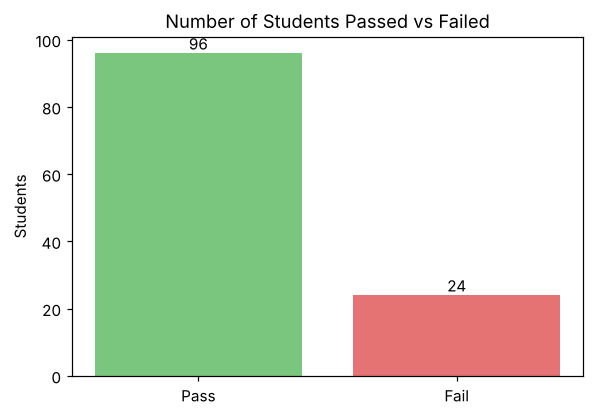

In [8]:
plt.figure(figsize=(6, 4))
counts = data["Result"].value_counts()
bars = plt.bar(counts.index, counts.values, color=["#7bc67e", "#e57373"])
plt.bar_label(bars)
plt.title("Number of Students Passed vs Failed"); plt.ylabel("Students")
plt.show()

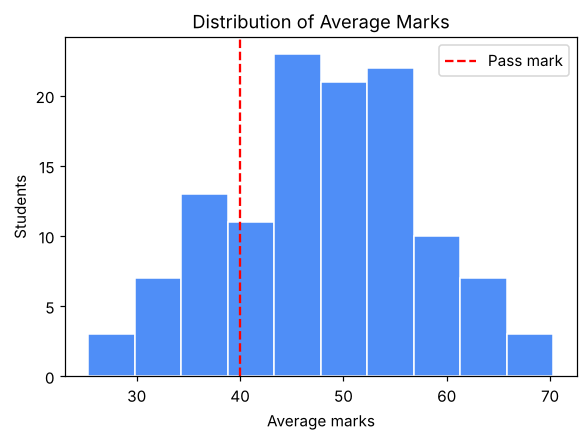

In [9]:
plt.figure(figsize=(6, 4))
plt.hist(data["Average"], bins=10, color="#4f8ef7", edgecolor="white")
plt.axvline(40, color="red", linestyle="--", label="Pass mark")
plt.title("Distribution of Average Marks"); plt.xlabel("Average marks"); plt.ylabel("Students"); plt.legend()
plt.show()

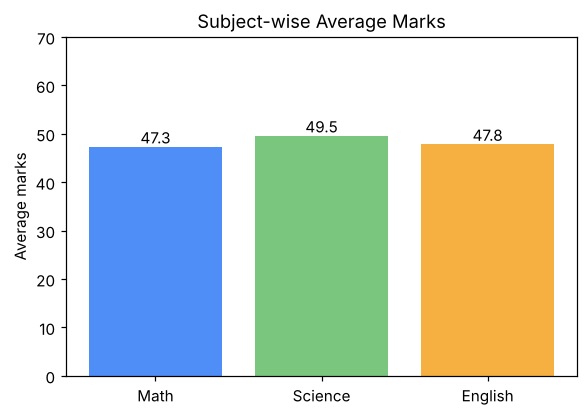

In [10]:
plt.figure(figsize=(6, 4))
sub = data[["Math", "Science", "English"]].mean()
bars = plt.bar(sub.index, sub.values, color=["#4f8ef7", "#7bc67e", "#f5b041"])
plt.bar_label(bars, fmt="%.1f")
plt.title("Subject-wise Average Marks"); plt.ylabel("Average marks"); plt.ylim(0, 70)
plt.show()

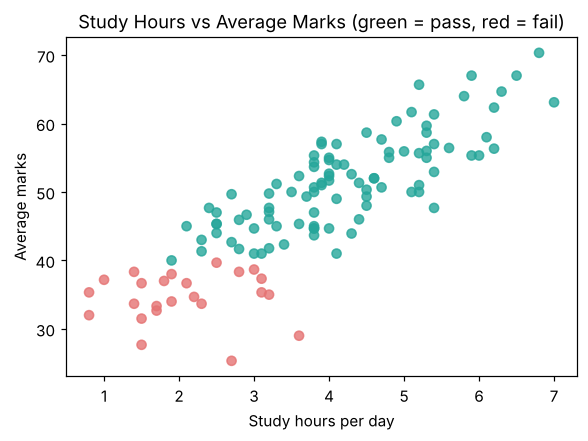

In [11]:
plt.figure(figsize=(6, 4))
colors = data["Result"].map({"Pass": "#26a69a", "Fail": "#e57373"})
plt.scatter(data["Study_Hours"], data["Average"], c=colors, alpha=0.8)
plt.title("Study Hours vs Average Marks (green = pass, red = fail)")
plt.xlabel("Study hours per day"); plt.ylabel("Average marks")
plt.show()

## 5. Conclusion
After removing 6 duplicate records and filling missing values, the dataset contains 120 students. The class average is 48.2 marks, with the highest student average at 70.33 and the lowest at 25.33. Taking 40 as the pass mark on the average score, 96 students (80%) passed and 24 (20%) failed. Science is the strongest subject (49.5), while Math (47.3) and English (47.8) are slightly lower.

The clearest insight is the link between study time and performance: study hours and average marks have a strong positive correlation of 0.84. Students who study 5 or more hours a day average about 58.4 marks, compared with only 38.8 for those studying under 3 hours, which is below the pass mark. Attendance shows only a weak relationship (0.10), and male and female students perform almost equally (48.0 vs 48.4). In short, regular study effort matters most for results, so low-study-hour students should be identified early and supported. The analysis also shows why data cleaning must be done before drawing conclusions.